In [2]:

# Manipulation des données
import numpy as np
import pandas as pd

# Visualisation des données
import matplotlib.pyplot as plt
import seaborn as sns

# Traitement du texte
import re

# Affichage des graphiques dans Jupyter
%matplotlib inline

# Configuration de l'affichage
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 150)

print("Les bibliothèques ont été importées avec succès !")


Les bibliothèques ont été importées avec succès !


In [3]:

# Charger la base de données
data = pd.read_csv("../Dataset_ProjetIA_food/moroccan_recipes_dataset.csv")

print("Base de données chargée avec succès !")


Base de données chargée avec succès !


In [ ]:
#La méthode head() permet d'afficher les cinq premiers enregistrements.
data.head()


,prompt,completion
0,"Recipe Name : Duck and prune tagine\n Description : Duck legs are the ultimate choice for low-and-slow cooking, as they become fall-apart tender w...","['Pour the oil into a heavy-based pan or casserole over a medium heat, then add the cinnamon sticks followed by the onions, garlic and a pinch of ..."
1,"Recipe Name : Potato tagine with baked halloumi\n Description : This North African-inspired potato dish is by no means an authentic tagine, but it...","['Heat the oven to 180°C fan/gas 6. Heat the oil in a large shallow ovenproof casserole or pan and fry the onions for 5 minutes. Add the garlic, g..."
2,"Recipe Name : Merguez sausages with crispy chickpeas and preserved lemon yogurt\n Description : Merguez sausages with crispy, roasted chickpeas ma...","['Heat the oven to 180°C fan/gas 6. Put the chickpeas in a large baking dish, ideally all in a single layer, then add the olive oil, spices and a ..."
3,Recipe Name : Chicken tagine casserole\n Description : Enjoy all the rich flavours of a chicken tagine with the convenience of a traybake-style ca...,['Heat the oven to 180ºC fan/gas 6. Slash the skin of the chicken with a sharp knife and put in a baking dish or shallow casserole with the onion ...
4,"Recipe Name : Preserved lemons\n Description : With only two basic ingredients and some imaginative flavourings, preserved lemons are storecupboar...","['Juice 4 of the lemons and set the juice aside. Cut the rest of the lemons lengthways into quarters, stopping three quarters of the way through s..."


In [ ]:
#La méthode shape permet de connaître le nombre de lignes et de colonnes.
print("Nombre de lignes :", data.shape[0])
print("Nombre de colonnes :", data.shape[1])


Nombre de lignes : 4627
Nombre de colonnes : 2


In [ ]:
#Cette instruction permet de connaître les attributs de notre base de données.
print("Les colonnes de la base de données :")
print(data.columns.tolist())


Les colonnes de la base de données :
['prompt', 'completion']


In [ ]:
#La méthode info() affiche les informations concernant les colonnes, les valeurs non nulles et les types de données.
data.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4627 entries, 0 to 4626
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   prompt      4627 non-null   object
 1   completion  4569 non-null   object
dtypes: object(2)
memory usage: 72.4+ KB


In [ ]:

#La méthode describe() permet d'obtenir des statistiques descriptives.
data.describe(include='all')


,prompt,completion
count,4627,4569
unique,4626,3905
top,"Recipe Name : Moroccan Lamb Stew with Preserved Lemons\n Ingredients : ['3 pounds boneless lamb stew meat, from the shoulder', '1 teaspoon ground ...",• Preheat oven to 180 C (350 F).
freq,2,5


In [ ]:

#Cette étape permet de détecter les colonnes qui contiennent des valeurs manquantes.
data.isnull().sum()


prompt         0
completion    58
dtype: int64

In [11]:
#Nous allons vérifier si certaines recettes sont enregistrées plusieurs fois.
print("Nombre de doublons :", data.duplicated().sum())

Nombre de doublons : 1


In [12]:
#Nous devons comprendre comment les informations d'une recette sont organisées dans le dataset.
print(data.iloc[0])

prompt        Recipe Name : Duck and prune tagine\n Description : Duck legs are the ultimate choice for low-and-slow cooking, as they become fall-apart tender w...
completion    ['Pour the oil into a heavy-based pan or casserole over a medium heat, then add the cinnamon sticks followed by the onions, garlic and a pinch of ...
Name: 0, dtype: object


In [13]:
#Nous allons vérifier si les deux colonnes contiennent des valeurs manquantes.
data.isnull().sum()


prompt         0
completion    58
dtype: int64

In [ ]:
#Nous allons vérifier si certaines recettes sont enregistrées plusieurs fois.
print("Nombre de doublons :", data.duplicated().sum())


Nombre de doublons : 1


In [16]:
#Pour notre système FoodMind AI, nous devons extraire les noms des recettes depuis la colonne prompt.
# Extraire les noms des recettes
data['Recipe_Name'] = data['prompt'].str.extract(r'Recipe Name\s*:\s*(.*)')

# Afficher les noms des 10 premières recettes
data[['Recipe_Name']].head(10)


,Recipe_Name
0,Duck and prune tagine
1,Potato tagine with baked halloumi
2,Merguez sausages with crispy chickpeas and preserved lemon yogurt
3,Chicken tagine casserole
4,Preserved lemons
5,Whole baked chicken with North African spices
6,Clodagh McKenna’s Moroccan spiced lamb chops
7,Root vegetable and lentil tagine
8,Fruity lamb and olive tagine
9,Spicy beef harira


In [ ]:
#Cette étape permet d'observer les recettes qui contiennent le mot Tagine.
tagine_recipes = data[
    data['Recipe_Name'].str.contains('tagine', case=False, na=False)
]

print("Nombre de recettes contenant Tagine :", len(tagine_recipes))

tagine_recipes[['Recipe_Name']].head(15)


Nombre de recettes contenant Tagine : 323


,Recipe_Name
0,Duck and prune tagine
1,Potato tagine with baked halloumi
3,Chicken tagine casserole
7,Root vegetable and lentil tagine
8,Fruity lamb and olive tagine
11,Leftover chicken tagine
12,Vegetable tagine
13,Knorr’s one-pot easy chicken tagine
14,Knorr’s one-pot fruity lamb tagine
22,Donal Skehan’s ultimate chicken tagine


In [ ]:
#Nous allons observer les types de recettes présents dans notre dataset à partir de quelques mots-clés.
keywords = ['tagine', 'couscous', 'harira', 'pastilla',
            'briouat', 'zaalouk', 'rfissa', 'kefta']

recipe_counts = {}

for word in keywords:
    recipe_counts[word] = data['Recipe_Name'].str.contains(
        word, case=False, na=False
    ).sum()

print(recipe_counts)


{'tagine': np.int64(323), 'couscous': np.int64(429), 'harira': np.int64(57), 'pastilla': np.int64(11), 'briouat': np.int64(12), 'zaalouk': np.int64(3), 'rfissa': np.int64(6), 'kefta': np.int64(34)}


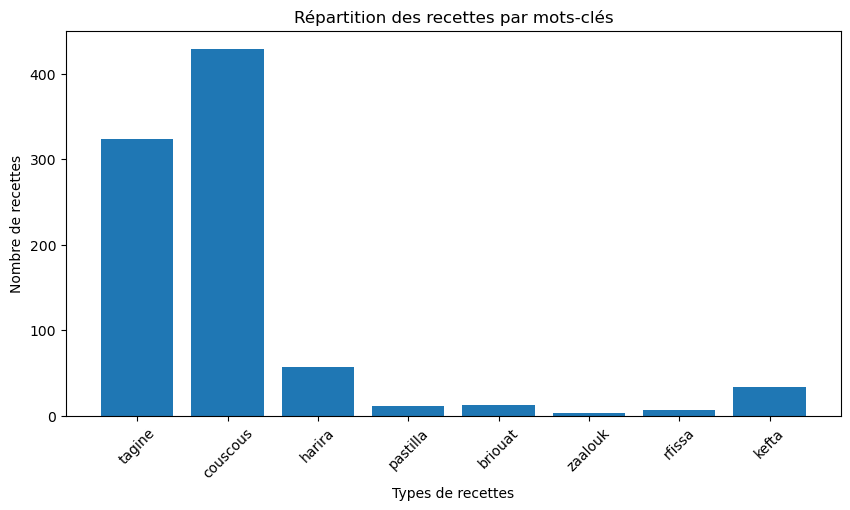

In [19]:

plt.figure(figsize=(10, 5))

plt.bar(recipe_counts.keys(), recipe_counts.values())

plt.title("Répartition des recettes par mots-clés")
plt.xlabel("Types de recettes")
plt.ylabel("Nombre de recettes")
plt.xticks(rotation=45)

plt.show()
